# real_sg2_record_session.ipynb — 키보드로 연속 수집 (맥북 저장)

한 번 실행하면 미리보기 창이 뜨고, 그 창이 켜진 동안 키로 에피소드를 계속 모읍니다.

| 키 | 동작 |
|---|---|
| `SPACE` | 녹화 시작 / 정지 (episode 번호 자동 증가) |
| `D` | 마지막으로 저장한 에피소드 삭제 |
| `Q` | 세션 종료 |

```
Orin (192.168.6.2)                                  MacBook
 ├─ ZMQ :5560 관절 상태 (outbound.py)      ──▶  세션 루프 ──▶ ~/aiworker_data/<task>/episode_NNN/
 ├─ ZMQ :5570 head  ZED left (camera_outbound.py) ▶ (미리보기)     joints.npz / meta.json
 ├─ ZMQ :5571 wrist_left  RealSense               ▶                rgb_<cam>.mp4 / rgb_<cam>_t.npy
 └─ ZMQ :5572 wrist_right RealSense               ▶
```

In [9]:
import os
if "__vsc_ipynb_file__" in globals(): os.chdir(os.path.dirname(__vsc_ipynb_file__))   # VS Code 커널 cwd 보정
%run ../package/init_project.py

import os, sys, time, json, shutil
from pathlib import Path
import numpy as np
import cv2
import zmq

from ri_motion_v5_package.utility import *   # ZMQPubSub



[ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /Users/yujin/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation


## 1. 설정

In [10]:
ROBOT_IP    = "192.168.6.2"
JOINT_PORT  = 5560
CAMERAS     = {"head": 5570, "wrist_left": 5571, "wrist_right": 5572}   # 이름: 포트 (camera_outbound.py 와 동일)

SAVE_ROOT   = Path.home() / "aiworker_data"
TASK_NAME   = "pick_and_place"
RECORD_HZ   = 30
MAX_SEC     = 120        # 에피소드당 안전 타임아웃
TARGET_N    = 50         # 목표 개수 (표시용)
TILE_H      = 360        # 미리보기 타일 높이

task_dir = SAVE_ROOT / TASK_NAME
task_dir.mkdir(parents=True, exist_ok=True)
print("save to:", task_dir)

save to: /Users/yujin/aiworker_data/pick_and_place


## 2. 유틸

In [11]:
def open_camera_sub(ip, port):
    s = zmq.Context.instance().socket(zmq.SUB)
    s.setsockopt(zmq.CONFLATE, 1)
    s.setsockopt(zmq.SUBSCRIBE, b"")
    s.setsockopt(zmq.RCVTIMEO, 1)
    s.connect(f"tcp://{ip}:{port}")
    return s

def recv_camera(sock):
    try:    return sock.recv_pyobj()
    except zmq.Again: return None

def decode_frame(msg):
    img = cv2.imdecode(np.frombuffer(msg["data"], dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None: return None
    return img[:, :img.shape[1] // 2, :] if msg.get("stereo", True) else img

def flatten_joints(robot_state):
    names, pos = [], []
    for grp, st in robot_state["joints"].items():
        names += list(st["name"]); pos += [float(p) for p in st["position"]]
    return names, np.asarray(pos, dtype=np.float64)

def list_episodes(task_dir):
    return sorted(p for p in task_dir.glob("episode_*") if (p / "meta.json").exists())

def next_episode_dir(task_dir):
    idx = 0
    while (task_dir / f"episode_{idx:03d}").exists(): idx += 1
    return task_dir / f"episode_{idx:03d}"


class EpisodeBuffer:
    """녹화 중 관절은 메모리에, 카메라는 카메라별 mp4 로 바로 쓰고 stop() 에서 나머지를 저장."""
    def __init__(self, ep_dir, hz, cam_names):
        self.ep_dir, self.hz = ep_dir, hz
        self.t0 = time.time()
        self.jt, self.jq, self.jnames = [], [], None
        self.rt = {c: [] for c in cam_names}
        self.writers = {}
        ep_dir.mkdir(parents=True)

    def elapsed(self): return time.time() - self.t0

    def add_joint(self, robot_state):
        names, q = flatten_joints(robot_state)
        if self.jnames is None: self.jnames = names
        self.jt.append(self.elapsed()); self.jq.append(q)

    def add_frame(self, cam, bgr):
        if cam not in self.writers:
            h, w = bgr.shape[:2]
            self.writers[cam] = cv2.VideoWriter(str(self.ep_dir / f"rgb_{cam}.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), self.hz, (w, h))
        self.writers[cam].write(bgr); self.rt[cam].append(self.elapsed())

    def _release(self):
        for w in self.writers.values(): w.release()

    def stop(self, task, robot_ip):
        self._release()
        np.savez(self.ep_dir / "joints.npz", t=np.asarray(self.jt), q=np.asarray(self.jq), names=np.asarray(self.jnames or []))
        for cam, ts in self.rt.items():
            if ts: np.save(self.ep_dir / f"rgb_{cam}_t.npy", np.asarray(ts))
        meta = dict(task=task, robot_ip=robot_ip, hz=self.hz, duration_sec=self.elapsed(),
                    n_joint_samples=len(self.jt), n_frames={c: len(ts) for c, ts in self.rt.items()},
                    cameras=list(self.rt), joint_names=self.jnames, recorded_at=time.strftime("%Y-%m-%d %H:%M:%S"))
        (self.ep_dir / "meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
        return meta

    def discard(self):
        self._release()
        shutil.rmtree(self.ep_dir, ignore_errors=True)


def tile_frames(frames, cam_names, tile_h):
    """카메라별 최신 프레임을 같은 높이로 맞춰 가로로 붙임 (없는 카메라는 검은 칸)."""
    tiles = []
    for c in cam_names:
        f = frames.get(c)
        if f is None:
            f = np.zeros((tile_h, tile_h * 4 // 3, 3), np.uint8)
            cv2.putText(f, "no signal", (20, tile_h // 2), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (80, 80, 80), 2)
        else:
            f = cv2.resize(f, (int(f.shape[1] * tile_h / f.shape[0]), tile_h))
        cv2.putText(f, c, (10, tile_h - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
        tiles.append(f)
    top = np.zeros((64, sum(t.shape[1] for t in tiles), 3), np.uint8)
    return np.vstack([top, np.hstack(tiles)])


def draw_hud(canvas, recording, ep_name, elapsed, n_done, target, msg, joint_hz, cam_hz):
    h, w = canvas.shape[:2]
    if recording:
        cv2.circle(canvas, (22, 22), 10, (0, 0, 255), -1)
        cv2.putText(canvas, f"REC {ep_name}  {elapsed:5.1f}s", (42, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    else:
        cv2.putText(canvas, "IDLE   [SPACE] start  [D] delete last  [Q] quit", (12, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2)
    cams = "  ".join(f"{c} {hz:3.0f}" for c, hz in cam_hz.items())
    cv2.putText(canvas, f"saved {n_done}/{target}   joint {joint_hz:4.0f}Hz   cam[Hz] {cams}   {msg}",
                (12, 54), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200, 200, 200), 1)
    if recording:
        cv2.rectangle(canvas, (0, 0), (w - 1, h - 1), (0, 0, 255), 4)
    return canvas

## 3. 연결

In [12]:
sub_joint = ZMQPubSub(role="sub", ip=ROBOT_IP, port=JOINT_PORT, verbose=True)
t0, n, last = time.time(), 0, None
while time.time() - t0 < 1.5:
    m = sub_joint.recv()
    if m is not None: n += 1; last = m
    time.sleep(1e-4)
assert last is not None, f"관절 상태 없음: tcp://{ROBOT_IP}:{JOINT_PORT}"
print(f"[joint] ≈{n/1.5:.0f} Hz, {len(flatten_joints(last)[0])} joints")

sub_cams = {}
for cam, port in CAMERAS.items():
    s = open_camera_sub(ROBOT_IP, port)
    t0, n, last = time.time(), 0, None
    while time.time() - t0 < 1.5:
        m = recv_camera(s)
        if m is not None: n += 1; last = m
        time.sleep(1e-3)
    if last is None:
        print(f"[camera] {cam:11s} 없음: tcp://{ROBOT_IP}:{port} → 제외"); s.close()
    else:
        sub_cams[cam] = s
        print(f"[camera] {cam:11s} ≈{n/1.5:.0f} Hz, {decode_frame(last).shape}")
print(f"[camera] 사용: {list(sub_cams) or '없음 (관절만 저장)'}")

print(f"[episodes] 이미 {len(list_episodes(task_dir))}개 있음 → 다음: {next_episode_dir(task_dir).name}")

[ZMQ Subscriber] pid:[11001] endpoint:[tcp://192.168.6.2:5560]
[ZMQ] role:[sub] ip:[192.168.6.2] port:[5560] hwm:[1] conflate:[True]
[joint] ≈85 Hz, 19 joints
[camera] head        ≈19 Hz, (376, 672, 3)
[camera] wrist_left  ≈19 Hz, (240, 424, 3)
[camera] wrist_right ≈15 Hz, (240, 424, 3)
[camera] 사용: ['head', 'wrist_left', 'wrist_right']
[episodes] 이미 1개 있음 → 다음: episode_001


## 4. 수집 세션
이 셀 하나로 여러 에피소드를 계속 모읍니다. 미리보기 창을 **클릭해서 포커스**를 준 뒤 키를 누르세요.


In [13]:
def run_session(sub_joint, sub_cams, task_dir, hz=30, max_sec=120, target_n=50, tile_h=360):
    WIN = "SG2 record session"
    cam_names = list(sub_cams)
    cv2.namedWindow(WIN, cv2.WINDOW_NORMAL)

    buf, last_saved, msg = None, None, "ready"
    frames = {}
    dt, t_next = 1.0 / hz, time.time()
    jc, cc, t_rate = 0, {c: 0 for c in cam_names}, time.time()
    joint_hz, cam_hz = 0.0, {c: 0.0 for c in cam_names}

    try:
        while True:
            now = time.time()
            if now < t_next:
                time.sleep(min(t_next - now, 1e-3)); continue
            t_next += dt

            # ---- 수신 ----
            m = sub_joint.recv()
            if m is not None:
                jc += 1
                if buf is not None: buf.add_joint(m)
            for cam, sock in sub_cams.items():
                cm = recv_camera(sock)
                if cm is None: continue
                bgr = decode_frame(cm)
                if bgr is None: continue
                cc[cam] += 1; frames[cam] = bgr
                if buf is not None: buf.add_frame(cam, bgr)

            # ---- 수신률 ----
            if now - t_rate >= 1.0:
                joint_hz = jc / (now - t_rate)
                cam_hz = {c: cc[c] / (now - t_rate) for c in cam_names}
                jc, cc, t_rate = 0, {c: 0 for c in cam_names}, now

            # ---- 타임아웃 ----
            if buf is not None and buf.elapsed() > max_sec:
                meta = buf.stop(TASK_NAME, ROBOT_IP); last_saved, buf = buf.ep_dir, None
                msg = f"timeout → saved {last_saved.name}"

            # ---- HUD + 키 ----
            n_done = len(list_episodes(task_dir))
            canvas = tile_frames(frames, cam_names, tile_h) if cam_names else np.zeros((64 + tile_h, 960, 3), np.uint8)
            canvas = draw_hud(canvas, buf is not None, buf.ep_dir.name if buf else "",
                              buf.elapsed() if buf else 0.0, n_done, target_n, msg, joint_hz, cam_hz)
            cv2.imshow(WIN, canvas)
            k = cv2.waitKey(1) & 0xFF

            if k == ord(" "):
                if buf is None:
                    buf = EpisodeBuffer(next_episode_dir(task_dir), hz, cam_names); msg = f"recording {buf.ep_dir.name}"
                else:
                    meta = buf.stop(TASK_NAME, ROBOT_IP); last_saved, buf = buf.ep_dir, None
                    nf = "/".join(str(v) for v in meta["n_frames"].values())
                    msg = f"saved {last_saved.name} ({meta['duration_sec']:.1f}s, {meta['n_joint_samples']} j / {nf} f)"
                    print("[saved]", msg)
            elif k in (ord("d"), ord("D")):
                if buf is not None:
                    buf.discard(); msg = f"discarded (recording) {buf.ep_dir.name}"; buf = None
                elif last_saved is not None and last_saved.exists():
                    shutil.rmtree(last_saved); msg = f"deleted {last_saved.name}"; print("[deleted]", last_saved.name); last_saved = None
                else:
                    msg = "nothing to delete"
            elif k in (ord("q"), ord("Q"), 27):
                if buf is not None:
                    buf.stop(TASK_NAME, ROBOT_IP); print("[saved on quit]", buf.ep_dir.name)
                break
    except KeyboardInterrupt:
        if buf is not None: buf.stop(TASK_NAME, ROBOT_IP); print("[saved on interrupt]", buf.ep_dir.name)
    finally:
        cv2.destroyAllWindows(); cv2.waitKey(1)
        print(f"[session end] total {len(list_episodes(task_dir))} episodes in {task_dir}")

run_session(sub_joint, sub_cams, task_dir, hz=RECORD_HZ, max_sec=MAX_SEC, target_n=TARGET_N, tile_h=TILE_H)

[saved] saved episode_001 (7.5s, 202 j / 123/127/125 f)
[deleted] episode_001
[saved] saved episode_001 (5.4s, 133 j / 90/79/87 f)
[session end] total 2 episodes in /Users/yujin/aiworker_data/pick_and_place


## 5. 수집 결과 확인

In [14]:
eps = list_episodes(task_dir)
print(f"{len(eps)} episodes in {task_dir}")
tot = 0.0
for e in eps:
    m = json.loads((e / "meta.json").read_text()); tot += m["duration_sec"]
    nf = m["n_frames"] if isinstance(m["n_frames"], dict) else {"rgb": m["n_frames"]}
    print(f"  {e.name}: {m['duration_sec']:5.1f}s  joints {m['n_joint_samples']:5d}  frames " + "  ".join(f"{c} {v}" for c, v in nf.items()))
print(f"total {tot/60:.1f} min")

2 episodes in /Users/yujin/aiworker_data/pick_and_place
  episode_000:   9.1s  joints   205  frames rgb 151
  episode_001:   5.4s  joints   133  frames head 90  wrist_left 79  wrist_right 87
total 0.2 min


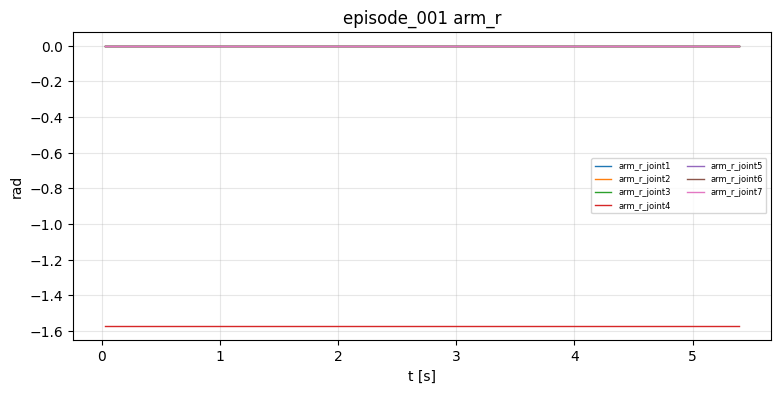

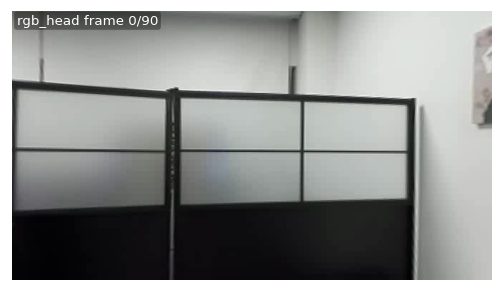

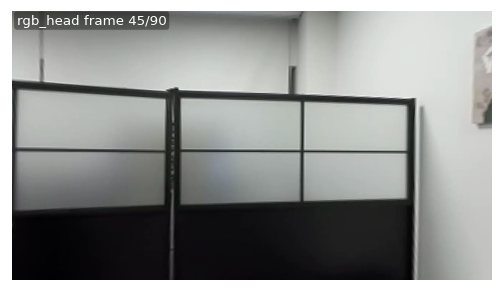

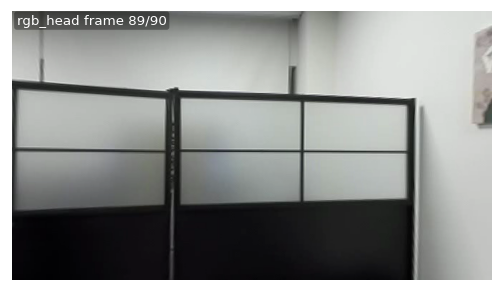

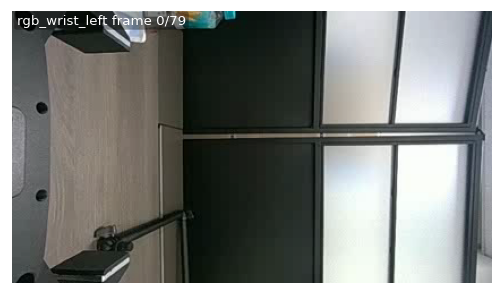

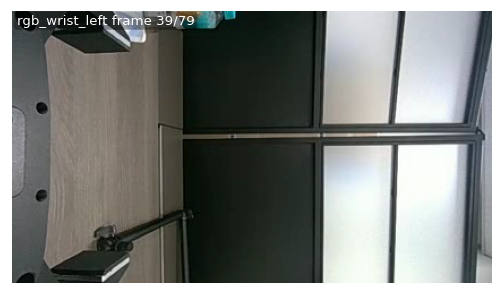

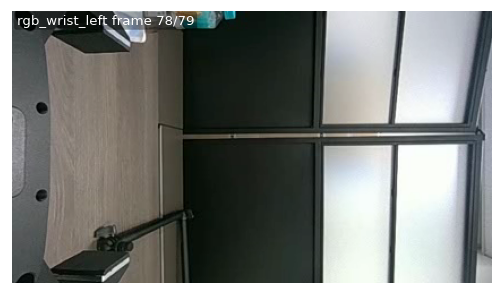

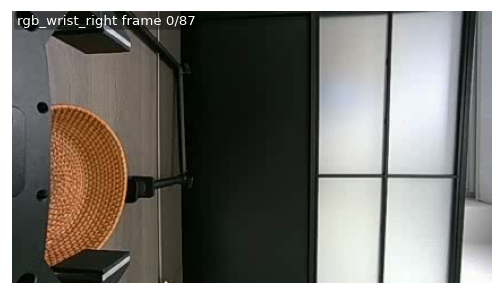

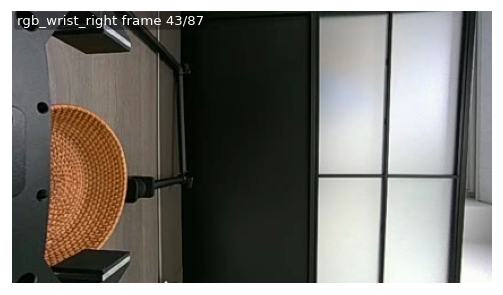

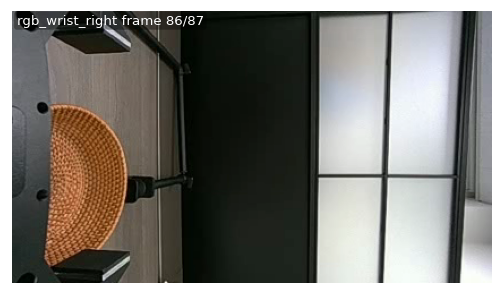

In [15]:
# 특정 에피소드 관절 궤적 / 카메라별 프레임 보기
import matplotlib.pyplot as plt
ep = eps[-1]
d = np.load(ep / "joints.npz", allow_pickle=True); t, q, names = d["t"], d["q"], list(d["names"])
plt.figure(figsize=(9, 4))
for i, n in enumerate(names):
    if n.startswith("arm_r"): plt.plot(t, q[:, i], label=n, lw=1)
plt.title(ep.name + " arm_r"); plt.xlabel("t [s]"); plt.ylabel("rad"); plt.legend(fontsize=6, ncol=2); plt.grid(alpha=.3); plt.show()

for vp in sorted(ep.glob("rgb_*.mp4")):
    cap = cv2.VideoCapture(str(vp)); nf = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for idx in (0, nf // 2, nf - 1):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx); ok, f = cap.read()
        if ok: imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), fig_w=4, title=f"{vp.stem} frame {idx}/{nf}", title_fs=8)
    cap.release()

## 6. 종료

In [16]:
sub_joint.close()
for s in sub_cams.values(): s.close()
print("closed.")

[ZMQ SUB] pid:[11001] Socket closed.
closed.


## 참고
- 세션을 끊었다가 다시 켜도 기존 `episode_*` 다음 번호부터 이어서 저장됩니다.
- 삭제(`D`)는 **직전 하나만** 됩니다. 더 지우려면 Finder에서 폴더를 지우거나 5번 셀에서 `shutil.rmtree`.
- 미리보기 창이 안 뜨거나 키가 안 먹으면 창을 한 번 클릭해서 포커스를 주세요. macOS 는 처음 실행 때 터미널/Jupyter 접근 권한을 물을 수 있습니다.
- 프레임 드롭(HUD 의 cam[Hz] 가 RECORD_HZ 보다 많이 낮음)이 보이면 `RECORD_HZ` 를 15~20 으로 낮추세요.
- 나중에 텔레옵 노트북(방식 2)으로 옮길 때는 `EpisodeBuffer` 클래스만 가져가서 텔레옵 루프 안에서 `add_joint / add_frame` 을 호출하면 됩니다.

- 카메라 3대는 Orin 의 `camera_outbound.py` 가 5570/5571/5572 로 보냅니다. 안 잡히는 카메라는 3번 셀에서 자동 제외됩니다.